### Calculate train-test similarity (S)

In [3]:
import json
trains = []
tests = []
for ps in ['k562_gwps','k562_essential','rpe1_essential','hepg2_essential','jurkat_essential']:
    for i in range(5):
        with open(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/presage_split/{ps}/test_splits_fold{i}.json','r') as f:
            fold_split = json.load(f)
        trains.append(fold_split['train'])
        tests.append(fold_split['test'])
    fold_splits = {}
    for i in range(5):
        fold_splits[f'fold_{i}']={'train':trains[i],'test':tests[i]}

    with open(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/presage_fold_{ps}.json','w') as f:
        json.dump(fold_splits, f)

In [4]:
import json
trains = []
tests = []
for ps in ['k562_gwps','k562_essential','rpe1_essential','hepg2_essential','jurkat_essential']:
    for i in range(5):
        with open(f'/home/jhpark/page-study/04.insilico-benchmark-temp/external_data/gears_split/{ps}/metadata_fold{i}.json','r') as f:
            fold_split = json.load(f)
        trains.append(fold_split['config']['train_conditions'])
        tests.append(fold_split['config']['test_conditions'])
    fold_splits = {}
    for i in range(5):
        fold_splits[f'fold_{i}']={'train':trains[i],'test':tests[i]}

    with open(f'/home/jhpark/page-study/04.insilico-benchmark-temp/external_data/gears_fold_{ps}.json','w') as f:
        json.dump(fold_splits, f)

In [ ]:
import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import matplotlib.pyplot as plt

def compute_distribution_shift_with_prefold(
    kernel1: pd.DataFrame,
    kernel2: pd.DataFrame,
    folds: dict,
    k: int = 5
) -> tuple[pd.DataFrame, float]:
    
    assert list(kernel1.index) == list(kernel2.index), "Indices must match"
    genes = np.array(kernel1.index)
    n = len(genes)
    records = []

    for fold, it in enumerate(folds.values()):
        train_genes = it['train']
        train_genes = list(set(genes).intersection(set(train_genes)))
        test_genes = it['test']
        test_genes = list(set(genes).intersection(set(test_genes)))

        for kernel, col in [(kernel1, "ds1"), (kernel2, "ds2")]:
            # sub-matrix: test rows x train columns
            sub = kernel.loc[test_genes, train_genes].values  # (n_test, n_train)

            # set self-similarity to nan if gene appears in both (shouldn't in CV)
            # top-k mean per test gene
            top_k_mean = np.sort(sub, axis=1)[:, -k:].mean(axis=1)  # (n_test,)

            for gene, score in zip(test_genes, top_k_mean):
                records.append({"gene": gene, "fold": fold, col: score})

    # merge ds1 and ds2 on (gene, fold)
    df = pd.DataFrame(records)
    df = (
        df.groupby(["gene", "fold"])
        .first()     
        .reset_index()
    )
    ds1 = df[df["ds1"].notna()][["gene", "fold", "ds1"]]
    ds2 = df[df["ds2"].notna()][["gene", "fold", "ds2"]]
    scores_df = ds1.merge(ds2, on=["gene", "fold"])

    r, p = pearsonr(scores_df["ds1"], scores_df["ds2"])
    return scores_df, r

In [ ]:
import pandas as pd
import json
ps_list = ['K562_GWPS', 'K562_Essential', 'RPE1_Essential', 'Jurkat_Essential', 'HepG2_Essential', 'HEK293_GWPS', 'HEK293_Essential', 'HCT116_GWPS', 'HCT116_Essential']

scores_df_result = {}
for prior in ['DepMap','genePT','Marbach','MsigDB','Periscope','scGPT','StringDB','Untangled']:
    scores_df_collate = []
    prior_kernel = pd.read_csv(f"/nas/project1/PAGE_HSim/out/02.prior_perturbseq/exported_kernels/prior_gene_kernels/{prior}.gene_x_gene.csv.gz", index_col=0)
    for ps in ps_list:
        with open(f'/workspaces/page-study/04.insilico-benchmark-temp/external_data/presage_fold_{ps.lower()}.json', 'r') as f:
            folds = json.load(f)
        ps_kernel = pd.read_csv("/nas/project1/PAGE_HSim/out/02.prior_perturbseq/exported_kernels/perturbseq_kernels/XAIRA_HCT116_GWPS/XAIRA_HCT116_GWPS.perturbation_x_perturbation.from_perturbseq.csv.gz", index_col=0)
        joint_idx = list(set(prior_kernel.index).intersection(ps_kernel))
        prior_kernel = prior_kernel.loc[joint_idx][joint_idx]
        ps_kernel = ps_kernel.loc[joint_idx][joint_idx]
        scores_df, r = compute_distribution_shift_with_prefold(prior_kernel, ps_kernel, k=5, folds=folds) # k=10, k=20
        scores_df_collate.append(scores_df)
    scores_df_result[prior] = scores_df_collate
    del prior_kernel, ps_kernel, scores_df, r, scores_df_collate

In [ ]:
for i in range(9):
    r_results = []
    genes = scores_df_result['DepMap'][i]['gene']
    for prior in ['DepMap','genePT','Marbach','MsigDB','Periscope','scGPT','StringDB','Untangled']:
        x, y = scores_df_result[prior][i]['ds1'], scores_df_result[prior][i]['ds2']
        r_results.append(x)
        if prior == 'Untangled':
            r_results.append(y)
    out_df = pd.concat(r_results, axis=1)
    out_df.columns = ['DepMap','genePT','Marbach','MsigDB','Periscope','scGPT','StringDB','Untangled','Ground Truth']
    out_df.index = genes
    out_df.to_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/{ps_list[i].lower()}_distribution_shift_score.csv')

### Fig.S4A, KNN (K=5, 10, 10) sensitivity

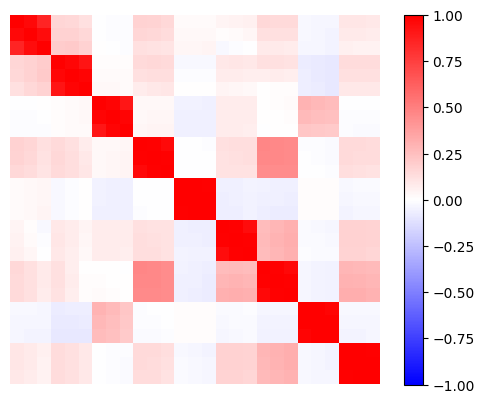

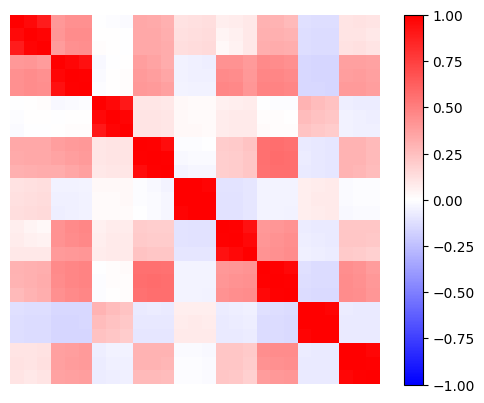

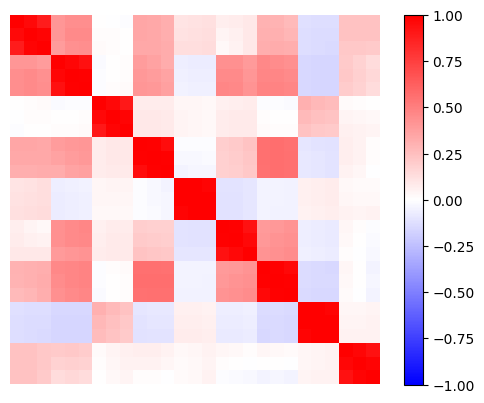

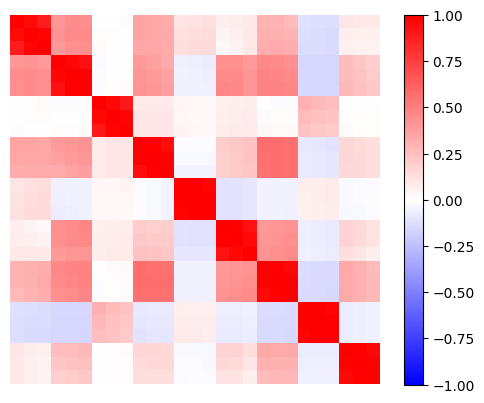

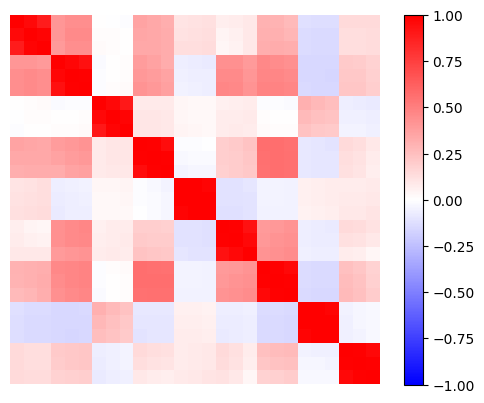

In [6]:
import pandas as pd

for ps in ['k562_gwps', 'k562_essential', 'rpe1_essential', 'hepg2_essential', 'jurkat_essential']:
    distshift_score_5 = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/{ps}_distribution_shift_score.csv').set_index('gene')
    distshift_score_10 = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/{ps}_distribution_shift_score_k10.csv').set_index('gene')
    distshift_score_20 = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/{ps}_distribution_shift_score_k20.csv').set_index('gene')
    plot_data = []
    for prior in distshift_score_5.columns:
        plot_data.append(distshift_score_5[prior])
        plot_data.append(distshift_score_10[prior])
        plot_data.append(distshift_score_20[prior])
    plot_df = pd.concat(plot_data, axis=1).T
    import matplotlib.pyplot as plt
    import numpy as np
    plt.imshow(np.corrcoef(plot_df), vmin=-1, vmax=1, cmap='bwr')
    plt.colorbar()
    plt.axis('off')
    #plt.savefig(f'./figure_out/Fig.S5A_{ps}.pdf')
    plt.show()

### Forecastability of "agreement-based" rubrics

In [2]:
import numpy as np
import pandas as pd

gene_level_local_metrics = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_local_overlap_allpair.csv')
gene_level_global_metrics = pd.read_csv('/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/gene_global_overlap_allpair.csv')
local_metrics = np.sum(gene_level_local_metrics.set_index('gene')>2.5, axis=0)/gene_level_local_metrics.shape[0]
global_metrics = np.sum(gene_level_global_metrics.set_index('gene')>2.5, axis=0)/gene_level_global_metrics.shape[0]
local_metrics = local_metrics.reset_index()
global_metrics = global_metrics.reset_index()
prior_z_score = (gene_level_local_metrics.set_index('gene').mean(axis=1)+gene_level_global_metrics.set_index('gene').mean(axis=1))/2
prior_intrinsic_scores = (gene_level_local_metrics.set_index('gene')+gene_level_global_metrics.set_index('gene'))/2

In [3]:
import pandas as pd
ps_list = ['k562_gwps','k562_essential','rpe1_essential','hepg2_essential','jurkat_essential']

In [4]:
import pandas as pd
gene_level_local_metrics = {}
gene_level_global_metrics = {}
analysis_targets = ['K562_GWPS','K562_Essential','RPE1_Essential','HepG2_Essential','Jurkat_Essential']
for analysis_target in analysis_targets: 
    gene_level_local_metrics[analysis_target.lower()] = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{analysis_target}_pertspace_gene_local_overlap_allpair.csv').set_index('gene')
    gene_level_global_metrics[analysis_target.lower()] = pd.read_csv(f'/home/jhpark/page_reproducibility/03_prior_perturbseq_compare/intermediate/{analysis_target}_pertspace_gene_global_overlap_allpair.csv').set_index('gene')

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
import json
import warnings

warnings.filterwarnings('ignore')

#fig, ax= plt.subplots(1, 9, figsize=(32, 4))
presage_intrinsic_corr = []
for i in range(len(ps_list)):
    results = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/presage_split/{ps_list[i]}/detailed_metrics.csv')

    plot_df = results[results.model=='presage'][results.metric=='weighted_r2_deltapert']
    #plot_df = results[results.model=='presage'][results.metric=='pearson_deltactrl_degs']
    plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[-1])
    plot_df = plot_df[['perturbation', 'value']]
    plot_df = plot_df.set_index('perturbation')
    joint_perts = list(prior_intrinsic_scores.index.intersection(plot_df.index))
    x = plot_df.loc[joint_perts].values[:, 0]
    y = prior_intrinsic_scores.loc[joint_perts].mean(axis=1).values

    presage_intrinsic_corr.append(pearsonr(x, y).statistic)

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
import json
import warnings

warnings.filterwarnings('ignore')

#fig, ax= plt.subplots(1, 9, figsize=(32, 4))
presage_cofunc_corr = []
for i in range(len(ps_list)):
    results = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/presage_split/{ps_list[i]}/detailed_metrics.csv')

    cofunc_scores = (gene_level_global_metrics[ps_list[i]]+gene_level_local_metrics[ps_list[i]])/2

            
    plot_df = results[results.model=='presage'][results.metric=='weighted_r2_deltapert']
    #plot_df = results[results.model=='presage'][results.metric=='pearson_deltactrl_degs']
    plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[-1])
    plot_df = plot_df[['perturbation', 'value']]
    plot_df = plot_df.set_index('perturbation')
    joint_perts = list(cofunc_scores.index.intersection(plot_df.index))
    x = plot_df.loc[joint_perts].values[:, 0]
    y = cofunc_scores.loc[joint_perts].mean(axis=1).values

    presage_cofunc_corr.append(pearsonr(x, y).statistic)

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
import json
import warnings

warnings.filterwarnings('ignore')

#fig, ax= plt.subplots(1, 9, figsize=(32, 4))
gears_intrinsic_corr = []
for i in range(len(ps_list)):
    fold_corr = []
    results = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/gears_split/{ps_list[i]}/detailed_metrics.csv')

    with open(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/presage_fold_{ps_list[i]}.json','r') as f:
        plot_df = results[results.model=='gears'][results.metric=='weighted_r2_deltapert']
        #plot_df = results[results.model=='gears'][results.metric=='pearson_deltactrl_degs']
        plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[-1])
        plot_df = plot_df[['perturbation', 'value']]
        plot_df = plot_df.set_index('perturbation')
        joint_perts = list(prior_intrinsic_scores.index.intersection(plot_df.index))
        x = plot_df.loc[joint_perts].values[:, 0]
        y = prior_intrinsic_scores.loc[joint_perts].mean(axis=1).values
    gears_intrinsic_corr.append(pearsonr(x,y).statistic)

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
import json
import warnings

warnings.filterwarnings('ignore')

#fig, ax= plt.subplots(1, 9, figsize=(32, 4))
gears_cofunc_corr = []
for i in range(len(ps_list)):
    results = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/gears_split/{ps_list[i]}/detailed_metrics.csv')

    cofunc_scores = (gene_level_global_metrics[ps_list[i]]+gene_level_local_metrics[ps_list[i]])/2
            
    plot_df = results[results.model=='gears'][results.metric=='weighted_r2_deltapert']
    #plot_df = results[results.model=='gears'][results.metric=='pearson_deltactrl_degs']
    plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[-1])
    plot_df = plot_df[['perturbation', 'value']]
    plot_df = plot_df.set_index('perturbation')
    joint_perts = list(cofunc_scores.index.intersection(plot_df.index))
    x = plot_df.loc[joint_perts].values[:, 0]
    y = cofunc_scores.loc[joint_perts].mean(axis=1).values

    gears_cofunc_corr.append(pearsonr(x, y).statistic)

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr, spearmanr
import json
import warnings

warnings.filterwarnings('ignore')

#fig, ax= plt.subplots(1, 9, figsize=(32, 4))
sclambda_intrinsic_corr = []
for i in range(len(ps_list)):
    results = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/sclambda_split/{ps_list[i]}/detailed_metrics.csv')

    plot_df = results[results.model=='sclambda'][results.metric=='weighted_r2_deltapert']
    #plot_df = results[results.model=='sclambda'][results.metric=='pearson_deltactrl_degs']
    plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[-1])
    plot_df = plot_df[['perturbation', 'value']]
    plot_df = plot_df.set_index('perturbation')
    joint_perts = list(prior_intrinsic_scores.index.intersection(plot_df.index))
    x = plot_df.loc[joint_perts].values[:, 0]
    y = prior_intrinsic_scores.loc[joint_perts].mean(axis=1).values

    sclambda_intrinsic_corr.append(pearsonr(x, y).statistic)

#fig, ax= plt.subplots(1, 9, figsize=(32, 4))
sclambda_cofunc_corr = []
for i in range(len(ps_list)):
    results = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/sclambda_split/{ps_list[i]}/detailed_metrics.csv')

    cofunc_scores = (gene_level_global_metrics[ps_list[i]]+gene_level_local_metrics[ps_list[i]])/2

            
    plot_df = results[results.model=='sclambda'][results.metric=='weighted_r2_deltapert']
    #plot_df = results[results.model=='sclambda'][results.metric=='pearson_deltactrl_degs']
    plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[-1])
    plot_df = plot_df[['perturbation', 'value']]
    plot_df = plot_df.set_index('perturbation')
    joint_perts = list(cofunc_scores.index.intersection(plot_df.index))
    x = plot_df.loc[joint_perts].values[:, 0]
    y = cofunc_scores.loc[joint_perts].mean(axis=1).values

    sclambda_cofunc_corr.append(pearsonr(x, y).statistic)

In [10]:
print(presage_intrinsic_corr)
print(presage_cofunc_corr)
print(gears_intrinsic_corr)
print(gears_cofunc_corr)
print(sclambda_intrinsic_corr)
print(sclambda_cofunc_corr)

[np.float64(0.408131004454264), np.float64(0.297128753635711), np.float64(0.33895170091631743), np.float64(0.3435439168961361), np.float64(0.2969369740691179)]
[np.float64(0.6504081090038178), np.float64(0.6037575615592118), np.float64(0.5741537279261449), np.float64(0.6736502832997194), np.float64(0.6312035213624877)]
[np.float64(0.011854278527520901), np.float64(0.037520173831672575), np.float64(0.20916601718545702), np.float64(0.1690988277336407), np.float64(0.16351557711114936)]
[np.float64(0.02061854926294357), np.float64(0.03889836133984334), np.float64(0.3866419686292511), np.float64(0.33444742277788986), np.float64(0.29855235269669056)]
[np.float64(0.35757300408356474), np.float64(0.2834987605183822), np.float64(0.2766081713342392), np.float64(0.2686125525278371), np.float64(0.3011454887962391)]
[np.float64(0.5175856646404327), np.float64(0.41119530888215805), np.float64(0.2936116219888982), np.float64(0.3904071582347942), np.float64(0.39043773793984066)]


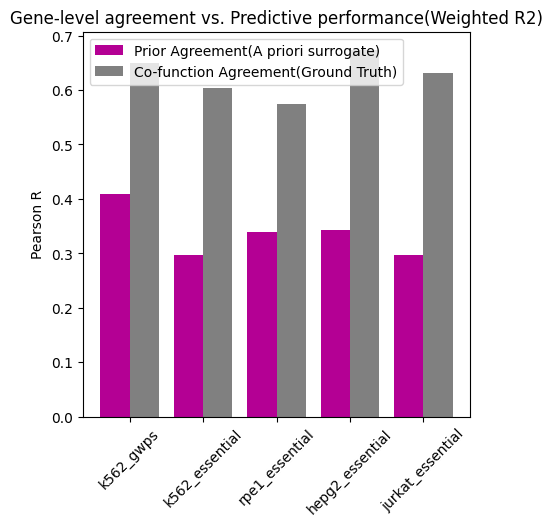

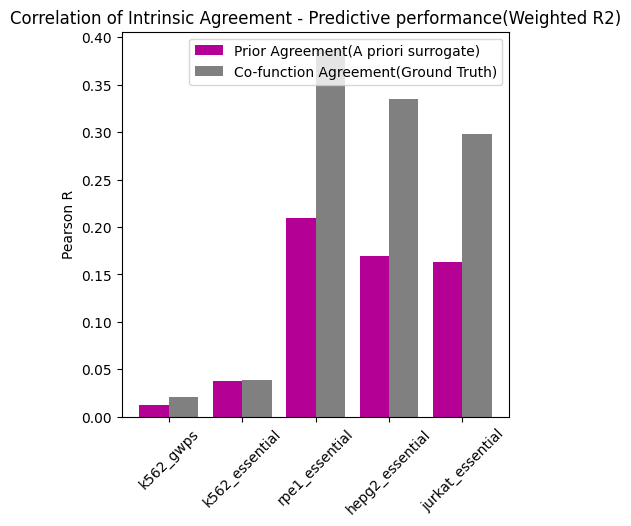

In [12]:
plt.figure(figsize=(5, 5))
plt.bar([x-0.2 for x in range(len(ps_list))], presage_intrinsic_corr, width=0.4, color='#B40094', label='Prior Agreement(A priori surrogate)')

plt.bar([x+0.2 for x in range(len(ps_list))], presage_cofunc_corr, width=0.4, color='grey', label='Co-function Agreement(Ground Truth)')
plt.xticks(ticks=range(5), labels=ps_list, rotation=45)
plt.title('Gene-level agreement vs. Predictive performance(Weighted R2)')
plt.ylabel('Pearson R')
plt.legend()
#plt.savefig('../figure_out/Final_Fig5_PRESAGE.pdf')

plt.figure(figsize=(5, 5))
plt.bar([x-0.2 for x in range(len(ps_list))], gears_intrinsic_corr, width=0.4, color='#B40094', label='Prior Agreement(A priori surrogate)')

plt.bar([x+0.2 for x in range(len(ps_list))], gears_cofunc_corr, width=0.4, color='grey', label='Co-function Agreement(Ground Truth)')
plt.xticks(ticks=range(5), labels=ps_list, rotation=45)
plt.title('Correlation of Intrinsic Agreement - Predictive performance(Weighted R2)')
plt.ylabel('Pearson R')
plt.legend()
#plt.savefig('../figure_out/Final_Fig5B_GEARS.pdf')

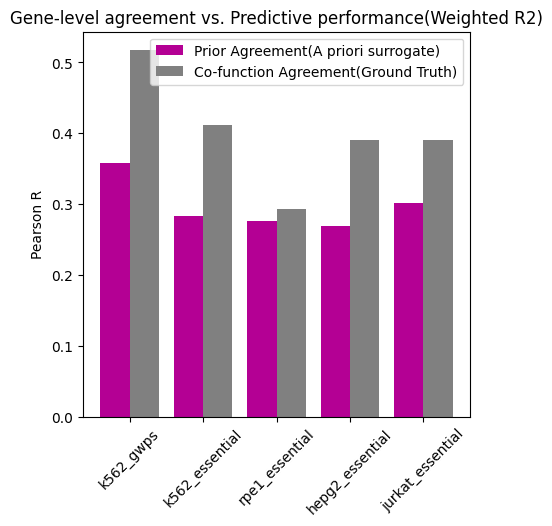

In [13]:
plt.figure(figsize=(5, 5))
plt.bar([x-0.2 for x in range(len(ps_list))], sclambda_intrinsic_corr, width=0.4, color='#B40094', label='Prior Agreement(A priori surrogate)')

plt.bar([x+0.2 for x in range(len(ps_list))], sclambda_cofunc_corr, width=0.4, color='grey', label='Co-function Agreement(Ground Truth)')
plt.xticks(ticks=range(5), labels=ps_list, rotation=45)
plt.title('Gene-level agreement vs. Predictive performance(Weighted R2)')
plt.ylabel('Pearson R')
plt.legend()
#plt.savefig('../figure_out/Final_Fig5_sclambda.pdf')

In [14]:
prediction_results = []
for i in range(len(ps_list)):
    results = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/gears_split/{ps_list[i]}/detailed_metrics.csv')
    plot_df = results[results.model=='gears'][results.metric=='weighted_r2_deltapert']
    #plot_df = results[results.model=='gears'][results.metric=='pearson_deltactrl_degs']
    plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[-1])
    plot_df = plot_df[['perturbation', 'value']]
    plot_df = plot_df.set_index('perturbation')
    joint_perts = list(prior_intrinsic_scores.index.intersection(plot_df.index))
    prediction_results.append(plot_df.loc[joint_perts].median())
for i in range(len(ps_list)):
    results = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/presage_split/{ps_list[i]}/detailed_metrics.csv')
    plot_df = results[results.model=='presage'][results.metric=='weighted_r2_deltapert']
    #plot_df = results[results.model=='gears'][results.metric=='pearson_deltactrl_degs']
    plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[-1])
    plot_df = plot_df[['perturbation', 'value']]
    plot_df = plot_df.set_index('perturbation')
    joint_perts = list(prior_intrinsic_scores.index.intersection(plot_df.index))
    prediction_results.append(plot_df.loc[joint_perts].median())
for i in range(len(ps_list)):
    results = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/sclambda_split/{ps_list[i]}/detailed_metrics.csv')
    plot_df = results[results.model=='sclambda'][results.metric=='weighted_r2_deltapert']
    #plot_df = results[results.model=='gears'][results.metric=='pearson_deltactrl_degs']
    plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[-1])
    plot_df = plot_df[['perturbation', 'value']]
    plot_df = plot_df.set_index('perturbation')
    joint_perts = list(prior_intrinsic_scores.index.intersection(plot_df.index))
    prediction_results.append(plot_df.loc[joint_perts].median())

Text(0, 0.5, 'Pearson R(Weighted R2 vs. Prior Agreement)')

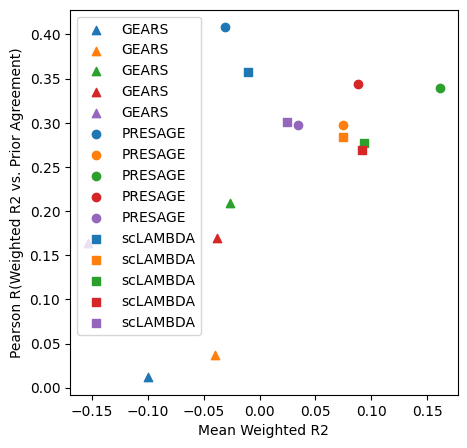

In [13]:
colors_rgba = plt.colormaps['tab10'].colors

plt.figure(figsize=(5,5))
for i in range(5):
    plt.scatter(prediction_results[i], gears_intrinsic_corr[i], color=colors_rgba[i], marker='^', label='GEARS')
for i in range(5):
    plt.scatter(prediction_results[5+i], presage_intrinsic_corr[i], color=colors_rgba[i], label='PRESAGE')
for i in range(5):
    plt.scatter(prediction_results[10+i], sclambda_intrinsic_corr[i], color=colors_rgba[i], marker='s', label='scLAMBDA')
plt.legend()
plt.xlabel('Mean Weighted R2')
plt.ylabel('Pearson R(Weighted R2 vs. Prior Agreement)')
#plt.savefig('../figure_out/Fig.5D.pdf')

### Train-test similarity based rubrics

In [ ]:
import pandas as pd
ps_list = ['k562_gwps','k562_essential','rpe1_essential','hepg2_essential','jurkat_essential'] #,'hek293_gwps', 'hek293_essential', 'hct116_gwps','hct116_essential']
ps_result = {}
for i in range(5):
    distshift_score = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/{ps_list[i]}_distribution_shift_score.csv', index_col=0)
    results = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/presage_split/{ps_list[i]}/detailed_metrics.csv')
    import matplotlib.pyplot as plt
    from scipy.stats import pearsonr, spearmanr
    #fig, ax= plt.subplots(10, 2, figsize=(8, 36))

    pearson_results_1 = []
    spearman_results_1 = []
    pearson_results_2 = []
    spearman_results_2 = []

    for idx, prior in enumerate(distshift_score.columns.tolist()[:-1]+['All Mixed','Ground Truth']):
        plot_df = results[results.model=='presage'][results.metric=='pearson_deltapert_degs']
        plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[-1])
        plot_df = plot_df[['perturbation', 'value']]
        plot_df = plot_df.set_index('perturbation')
        joint_perts = list(set(plot_df.index).intersection(distshift_score.index))
        x = plot_df.loc[joint_perts].values[:, 0]
        if 'Mixed' in prior:
            if prior == 'All Mixed':
                y = distshift_score.loc[joint_perts][['StringDB','genePT','MsigDB','scGPT','DepMap']].max(axis=1).values
        else:
            y = distshift_score.loc[joint_perts][prior].values

        pearson_results_1.append(pearsonr(x, y).statistic)
        spearman_results_1.append(spearmanr(x, y).statistic)

        plot_df = results[results.model=='presage'][results.metric=='weighted_r2_deltapert']
        plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[-1])
        plot_df = plot_df[['perturbation', 'value']]
        plot_df = plot_df.set_index('perturbation')
        joint_perts = list(set(plot_df.index).intersection(distshift_score.index))
        x = plot_df.loc[joint_perts].values[:, 0]

        if 'Mixed' in prior:
            if prior == 'All Mixed':
                y = distshift_score.loc[joint_perts][['StringDB','genePT','MsigDB','scGPT','DepMap']].max(axis=1).values
        else:
            y = distshift_score.loc[joint_perts][prior].values

        pearson_results_2.append(pearsonr(x, y).statistic)
        spearman_results_2.append(spearmanr(x, y).statistic)

    
    ps_result[ps_list[i]] = pearson_results_2

/tmp/ipykernel_3893161/3682866537.py:17: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  plot_df = results[results.model=='presage'][results.metric=='pearson_deltapert_degs']
/tmp/ipykernel_3893161/3682866537.py:36: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  plot_df = results[results.model=='presage'][results.metric=='weighted_r2_deltapert']
/tmp/ipykernel_3893161/3682866537.py:17: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  plot_df = results[results.model=='presage'][results.metric=='pearson_deltapert_degs']
/tmp/ipykernel_3893161/3682866537.py:36: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  plot_df = results[results.model=='presage'][results.metric=='weighted_r2_deltapert']
/tmp/ipykernel_3893161/3682866537.py:17: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  plot_df = results[results.model=='presage'][results.metric=='pe

In [2]:
plot_df = pd.DataFrame(ps_result, index = distshift_score.columns.tolist()[:-1]+['Consensus','Co-function'])
plot_df = plot_df.loc[plot_df.T.mean().sort_values().index[::-1]]
predictability_against_distshift_presage = list(plot_df.T['Consensus'].values)

/tmp/ipykernel_3893161/2963320822.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels=plot_df.index.tolist(), rotation=45)


<Axes: title={'center': 'Train-Test Similarity vs. Prediction Performance'}, ylabel='Pearson R (vs. PRESAGE Weighted R2)'>

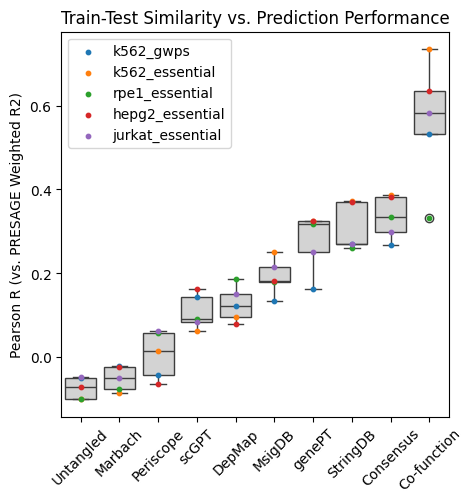

In [3]:
import seaborn as sns
plot_df = pd.DataFrame(ps_result, index = distshift_score.columns.tolist()[:-1]+['Consensus','Co-function'])
plot_df = plot_df.loc[plot_df.T.mean().sort_values().index]
fig, ax = plt.subplots(1,1,figsize=(5,5))
ax.set_xticklabels(labels=plot_df.index.tolist(), rotation=45)
for i in range(5):
    ax.scatter(range(10), plot_df.T.iloc[i], s=10, label=ps_list[i])
plt.legend()
plt.ylabel('Pearson R (vs. PRESAGE Weighted R2)')
plt.title('Train-Test Similarity vs. Prediction Performance')
sns.boxplot(plot_df.T, color='lightgrey', ax=ax, zorder=0)
#plt.savefig('../figure_out/Fig5E_PRESAGE.pdf')

In [4]:
ps_result = {}
for i in range(5):
    distshift_score = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/{ps_list[i]}_distribution_shift_score.csv', index_col=0)
    results = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/gears_split/{ps_list[i]}/detailed_metrics.csv')
    import matplotlib.pyplot as plt
    from scipy.stats import pearsonr, spearmanr
    #fig, ax= plt.subplots(10, 2, figsize=(8, 36))

    pearson_results_1 = []
    spearman_results_1 = []
    pearson_results_2 = []
    spearman_results_2 = []

    for idx, prior in enumerate(distshift_score.columns.tolist()[:-1]+['All Mixed','Ground Truth']):
        plot_df = results[results.model=='gears'][results.metric=='pearson_deltapert_degs']
        plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[1])
        plot_df = plot_df[['perturbation', 'value']]
        plot_df = plot_df.set_index('perturbation')
        joint_perts = list(set(plot_df.index).intersection(distshift_score.index))
        x = plot_df.loc[joint_perts].values[:, 0]
        if 'Mixed' in prior:
            if prior == 'All Mixed':
                y = distshift_score.loc[joint_perts][['StringDB','genePT','MsigDB','scGPT','DepMap']].mean(axis=1).values
        else:
            y = distshift_score.loc[joint_perts][prior].values

        pearson_results_1.append(pearsonr(x, y).statistic)
        spearman_results_1.append(spearmanr(x, y).statistic)

        plot_df = results[results.model=='gears'][results.metric=='weighted_r2_deltapert']
        plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[1])
        plot_df = plot_df[['perturbation', 'value']]
        plot_df = plot_df.set_index('perturbation')
        joint_perts = list(set(plot_df.index).intersection(distshift_score.index))
        x = plot_df.loc[joint_perts].values[:, 0]

        if 'Mixed' in prior:
            if prior == 'All Mixed':
                y = distshift_score.loc[joint_perts][['StringDB','genePT','MsigDB','scGPT','DepMap']].mean(axis=1).values
        else:
            y = distshift_score.loc[joint_perts][prior].values

        pearson_results_2.append(pearsonr(x, y).statistic)
        spearman_results_2.append(spearmanr(x, y).statistic)

    
    ps_result[ps_list[i]] = pearson_results_2

/tmp/ipykernel_3893161/1288995013.py:15: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  plot_df = results[results.model=='gears'][results.metric=='pearson_deltapert_degs']
/tmp/ipykernel_3893161/1288995013.py:30: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  plot_df = results[results.model=='gears'][results.metric=='weighted_r2_deltapert']
/tmp/ipykernel_3893161/1288995013.py:15: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  plot_df = results[results.model=='gears'][results.metric=='pearson_deltapert_degs']
/tmp/ipykernel_3893161/1288995013.py:30: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  plot_df = results[results.model=='gears'][results.metric=='weighted_r2_deltapert']
/tmp/ipykernel_3893161/1288995013.py:15: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  plot_df = results[results.model=='gears'][results.metric=='pearson_delt

In [5]:
plot_df = pd.DataFrame(ps_result, index = distshift_score.columns.tolist()[:-1]+['Consensus','Co-function'])
plot_df = plot_df.loc[plot_df.T.mean().sort_values().index[::-1]]
predictability_against_distshift_gears = list(plot_df.T['Consensus'].values)

/tmp/ipykernel_3893161/764830607.py:5: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(labels=plot_df.index.tolist(), rotation=45)


<Axes: title={'center': 'Train-Test Dissimilarity vs. Prediction Performance'}, ylabel='Pearson R (vs. GEARS Weighted R2)'>

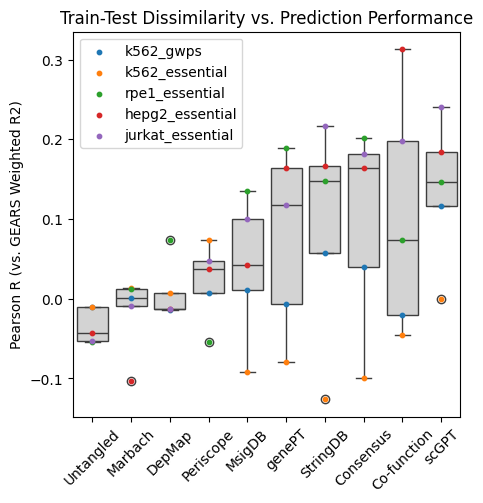

In [7]:
import seaborn as sns
plot_df = pd.DataFrame(ps_result, index = distshift_score.columns.tolist()[:-1]+['Consensus','Co-function'])
plot_df = plot_df.loc[plot_df.T.mean().sort_values().index]
fig, ax = plt.subplots(1,1,figsize=(5,5))
ax.set_xticklabels(labels=plot_df.index.tolist(), rotation=45)
for i in range(5):
    ax.scatter(range(10), plot_df.T.iloc[i], s=10, label=ps_list[i])
plt.legend()
plt.ylabel('Pearson R (vs. GEARS Weighted R2)')
plt.title('Train-Test Dissimilarity vs. Prediction Performance')
sns.boxplot(plot_df.T, color='lightgrey', ax=ax, zorder=0)
#plt.savefig('../figure_out/Fig5D_GEARS.pdf')

/tmp/ipykernel_3893161/1115935114.py:16: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  plot_df = results[results.model=='sclambda'][results.metric=='pearson_deltapert_degs']
/tmp/ipykernel_3893161/1115935114.py:35: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  plot_df = results[results.model=='sclambda'][results.metric=='weighted_r2_deltapert']
/tmp/ipykernel_3893161/1115935114.py:16: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  plot_df = results[results.model=='sclambda'][results.metric=='pearson_deltapert_degs']
/tmp/ipykernel_3893161/1115935114.py:35: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  plot_df = results[results.model=='sclambda'][results.metric=='weighted_r2_deltapert']
/tmp/ipykernel_3893161/1115935114.py:16: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  plot_df = results[results.model=='sclambda'][results.metric

<Axes: title={'center': 'Train-Test Similarity vs. Prediction Performance'}, ylabel='Pearson R (vs. sclambda Weighted R2)'>

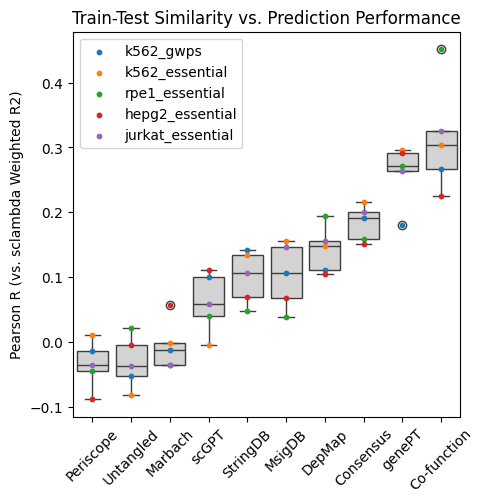

In [ ]:
ps_list = ['k562_gwps','k562_essential','rpe1_essential','hepg2_essential','jurkat_essential'] #,'hek293_gwps', 'hek293_essential', 'hct116_gwps','hct116_essential']
ps_result = {}
for i in range(5):
    distshift_score = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/{ps_list[i]}_distribution_shift_score.csv', index_col=0)
    results = pd.read_csv(f'/home/jhpark/page_reproducibility/05_forecastability/intermediate/sclambda_split/{ps_list[i]}/detailed_metrics.csv')
    import matplotlib.pyplot as plt
    from scipy.stats import pearsonr, spearmanr
    #fig, ax= plt.subplots(10, 2, figsize=(8, 36))

    pearson_results_1 = []
    spearman_results_1 = []
    pearson_results_2 = []
    spearman_results_2 = []

    for idx, prior in enumerate(distshift_score.columns.tolist()[:-1]+['All Mixed','Ground Truth']):
        plot_df = results[results.model=='sclambda'][results.metric=='pearson_deltapert_degs']
        plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[-1])
        plot_df = plot_df[['perturbation', 'value']]
        plot_df = plot_df.set_index('perturbation')
        joint_perts = list(set(plot_df.index).intersection(distshift_score.index))
        x = plot_df.loc[joint_perts].values[:, 0]
        if 'Mixed' in prior:
            if prior == 'All Mixed':
                y = distshift_score.loc[joint_perts][['StringDB','genePT','MsigDB','scGPT','DepMap']].max(axis=1).values
        else:
            y = distshift_score.loc[joint_perts][prior].values

        pearson_results_1.append(pearsonr(x, y).statistic)
        spearman_results_1.append(spearmanr(x, y).statistic)

        plot_df = results[results.model=='sclambda'][results.metric=='weighted_r2_deltapert']
        plot_df['perturbation'] = plot_df['perturbation'].apply(lambda x: x.split('_')[-1])
        plot_df = plot_df[['perturbation', 'value']]
        plot_df = plot_df.set_index('perturbation')
        joint_perts = list(set(plot_df.index).intersection(distshift_score.index))
        x = plot_df.loc[joint_perts].values[:, 0]

        if 'Mixed' in prior:
            if prior == 'All Mixed':
                y = distshift_score.loc[joint_perts][['StringDB','genePT','MsigDB','scGPT','DepMap']].max(axis=1).values
        else:
            y = distshift_score.loc[joint_perts][prior].values


        pearson_results_2.append(pearsonr(x, y).statistic)
        spearman_results_2.append(spearmanr(x, y).statistic)

    
    ps_result[ps_list[i]] = pearson_results_2
    
plot_df = pd.DataFrame(ps_result, index = distshift_score.columns.tolist()[:-1]+['Consensus','Co-function'])
plot_df = plot_df.loc[plot_df.T.mean().sort_values().index[::-1]]
predictability_against_distshift_sclambda = list(plot_df.T['Consensus'].values)
import seaborn as sns
plot_df = pd.DataFrame(ps_result, index = distshift_score.columns.tolist()[:-1]+['Consensus','Co-function'])
plot_df = plot_df.loc[plot_df.T.mean().sort_values().index]
fig, ax = plt.subplots(1,1,figsize=(5,5))
ax.set_xticklabels(labels=plot_df.index.tolist(), rotation=45)
for i in range(5):
    ax.scatter(range(10), plot_df.T.iloc[i], s=10, label=ps_list[i])
plt.legend()
plt.ylabel('Pearson R (vs. sclambda Weighted R2)')
plt.title('Train-Test Similarity vs. Prediction Performance')
sns.boxplot(plot_df.T, color='lightgrey', ax=ax, zorder=0)
#plt.savefig('../figure_out/Fig5E_sclambda.pdf')

In [9]:
print(predictability_against_distshift_presage)
print(predictability_against_distshift_gears)
print(predictability_against_distshift_sclambda)

[np.float64(0.2670091774693933), np.float64(0.3863156620896908), np.float64(0.335024686202926), np.float64(0.38291520142549756), np.float64(0.29945462215688307)]
[np.float64(0.03922890810371413), np.float64(-0.09957979320981507), np.float64(0.2020698615713152), np.float64(0.16359168916570685), np.float64(0.18185551538957237)]
[np.float64(0.191853140634107), np.float64(0.21598122529216182), np.float64(0.1596537868615971), np.float64(0.15083735612095472), np.float64(0.2003033739162319)]


(np.float64(0.5226776562336521),
 np.float64(0.43214285714285705),
 np.float64(0.04560672476288129),
 np.float64(0.10769303754639799))

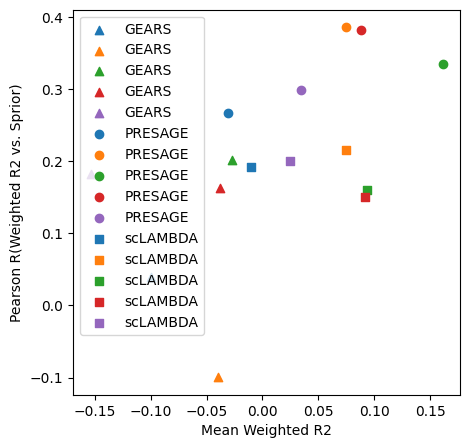

In [ ]:
predictability_against_distshift = predictability_against_distshift_gears+predictability_against_distshift_presage+predictability_against_distshift_sclambda
colors_rgba = plt.colormaps['tab10'].colors

plt.figure(figsize=(5,5))
for i in range(5):
    plt.scatter(prediction_results[i], predictability_against_distshift_gears[i], color=colors_rgba[i], marker='^', label='GEARS')
for i in range(5):
    plt.scatter(prediction_results[5+i], predictability_against_distshift_presage[i], color=colors_rgba[i], label='PRESAGE')
for i in range(5):
    plt.scatter(prediction_results[10+i], predictability_against_distshift_sclambda[i], color=colors_rgba[i], marker='s', label='scLAMBDA')
plt.legend()
plt.xlabel('Mean Weighted R2')
plt.ylabel('Pearson R(Weighted R2 vs. Sprior)')
#plt.savefig('../figure_out/Fig.5F.pdf')
pearsonr(np.array(prediction_results)[:, 0], np.array(predictability_against_distshift)).statistic, spearmanr(np.array(prediction_results)[:, 0], np.array(predictability_against_distshift)).statistic, pearsonr(np.array(prediction_results)[:, 0], np.array(predictability_against_distshift)).pvalue, spearmanr(np.array(prediction_results)[:, 0], np.array(predictability_against_distshift)).pvalue 